<a href="https://colab.research.google.com/github/Ana-Beatriz-N/ProcessamentoDeImagens/blob/main/2BimestrePortfolio1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import matplotlib.pyplot as plt
from skimage import data
import numpy as np

In [2]:
img = data.camera()

In [3]:
def convolucao(img, kernel):
    altura, largura = img.shape
    k_altura, k_largura = kernel.shape

    pad_altura = k_altura // 2
    pad_largura = k_largura // 2

    img_padded = np.pad(
        img,
        ((pad_altura, pad_altura),
         (pad_largura, pad_largura)),
        mode='constant'
    )

    resultado = np.zeros((altura, largura), dtype=np.float64)

    for i in range(altura):
        for j in range(largura):

            regiao = img_padded[
                i:i+k_altura,
                j:j+k_largura
            ]

            resultado[i, j] = np.sum(regiao * kernel)

    resultado = np.clip(resultado, 0, 255)

    return resultado.astype(np.uint8)


In [4]:
def filtro_media(img, kernelsize):

    kernel = np.ones((kernelsize, kernelsize), dtype=np.float64)

    kernel = kernel / np.sum(kernel)

    return convolucao(img, kernel)

In [5]:
def filtro_mediana(img, kernelsize):

    altura, largura = img.shape
    pad = kernelsize // 2

    img_padded = np.pad(
        img,
        ((pad, pad), (pad, pad)),
        mode='constant'
    )

    resultado = np.zeros_like(img)

    for i in range(altura):
        for j in range(largura):

            regiao = img_padded[
                i:i+kernelsize,
                j:j+kernelsize
            ]

            resultado[i, j] = np.median(regiao)

    return resultado

In [6]:
def filtro_moda(img, kernelsize):

    altura, largura = img.shape
    pad = kernelsize // 2

    img_padded = np.pad(
        img,
        ((pad, pad), (pad, pad)),
        mode='constant'
    )

    resultado = np.zeros_like(img)

    for i in range(altura):
        for j in range(largura):

            regiao = img_padded[
                i:i+kernelsize,
                j:j+kernelsize
            ]

            pixels = regiao.flatten()

            valores, frequencias = np.unique(
                pixels,
                return_counts=True
            )

            resultado[i, j] = valores[np.argmax(frequencias)]

    return resultado


In [7]:
def filtro_maxima(img, kernelsize):

    altura, largura = img.shape
    pad = kernelsize // 2

    img_padded = np.pad(
        img,
        ((pad, pad), (pad, pad)),
        mode='constant'
    )

    resultado = np.zeros_like(img)

    for i in range(altura):
        for j in range(largura):

            regiao = img_padded[
                i:i+kernelsize,
                j:j+kernelsize
            ]

            resultado[i, j] = np.max(regiao)

    return resultado

In [8]:
def implot(img, img_filtrada, nome_filtro, kernelsize):

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.title('Imagem original')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_filtrada, cmap='gray', vmin=0, vmax=255)
    plt.title(nome_filtro + ' - ' + str(kernelsize) + 'x' + str(kernelsize))
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [13]:
kernelsize = 5

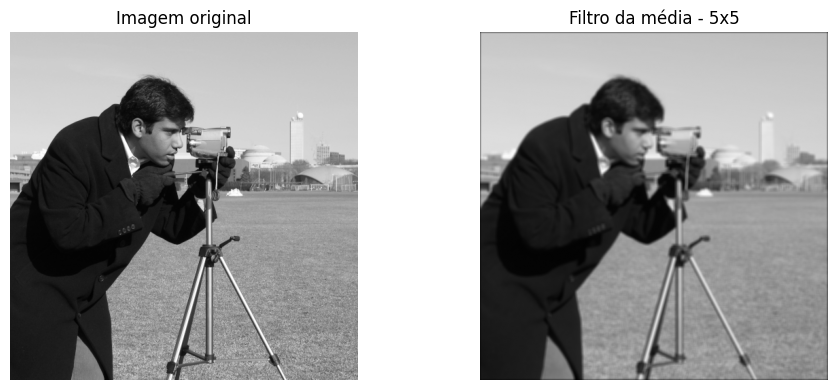

In [10]:
img_media = filtro_media(img, kernelsize)
implot(img, img_media, 'Filtro da média', kernelsize)

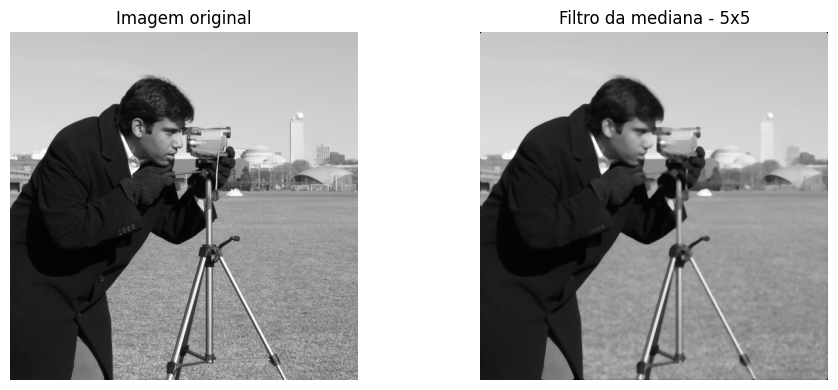

In [11]:
img_mediana = filtro_mediana(img, kernelsize)
implot(img, img_mediana, 'Filtro da mediana', kernelsize)

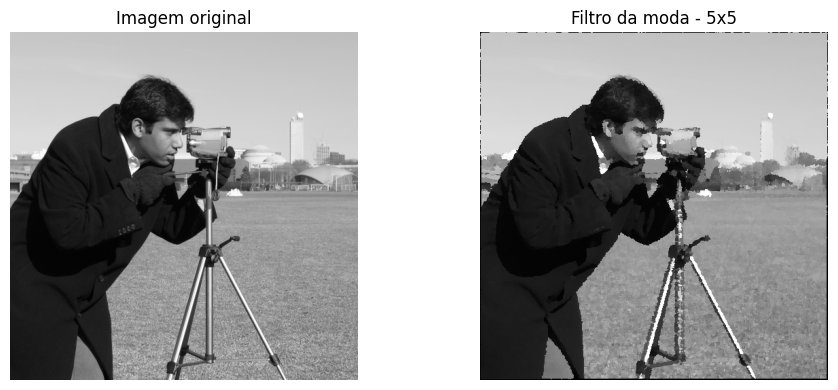

In [12]:
img_moda = filtro_moda(img, kernelsize)
implot(img, img_moda, 'Filtro da moda', kernelsize)

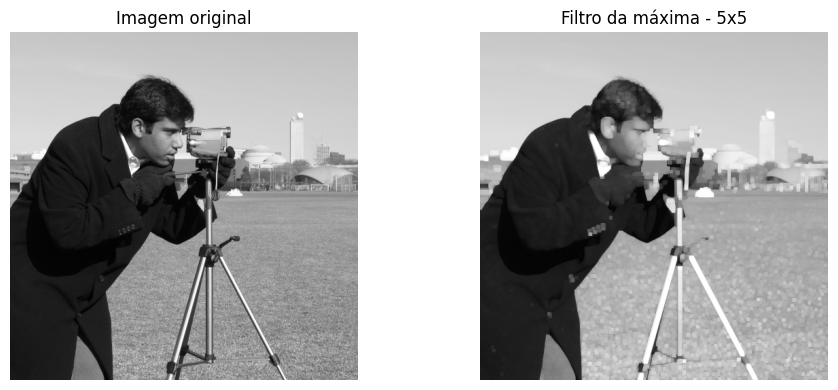

In [14]:
img_maxima = filtro_maxima(img, kernelsize)
implot(img, img_maxima, 'Filtro da máxima', kernelsize)